In [53]:
#import libraries
import pandas as pd                 # for working with tables
import numpy as np                  # for numbers
import matplotlib.pyplot as plt     # for graphs
import seaborn as sns               # for nicer graphs

from sklearn.model_selection import train_test_split   # split data into train and test
from sklearn.linear_model import LinearRegression      # our prediction model
from sklearn.metrics import r2_score, mean_absolute_error

print("Libraries loaded ✅")

Libraries loaded ✅


In [55]:
from google.colab import files
uploaded = files.upload()

Saving data.csv to data.csv


In [54]:
#read the file into a table (dataframe)
import pandas as pd

file_name = list(uploaded.keys())[0]   # get the name of the uploaded file
df = pd.read_csv('/content/data (1).csv')

print("File loaded:", file_name)
df.head()      # show first 5 rows

File loaded: data (1).csv


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [13]:
#understand the data
print("Rows and columns:", df.shape)
print()
df.info()

Rows and columns: (11914, 16)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  object 
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  object 
 7   Driven_Wheels      11914 non-null  object 
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   object 
 10  Vehicle Size       11914 non-null  object 
 11  Vehicle Style      11914 non-null  object 
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int6

In [14]:
# Basic statistics (min, max, average...)
df.describe()

,Year,Engine HP,Engine Cylinders,Number of Doors,highway MPG,city mpg,Popularity,MSRP
count,11914.000000,11845.00000,11884.000000,11908.000000,11914.000000,11914.000000,11914.000000,1.191400e+04
mean,2010.384338,249.38607,5.628829,3.436093,26.637485,19.733255,1554.911197,4.059474e+04
std,7.579740,109.19187,1.780559,0.881315,8.863001,8.987798,1441.855347,6.010910e+04
min,1990.000000,55.00000,0.000000,2.000000,12.000000,7.000000,2.000000,2.000000e+03
25%,2007.000000,170.00000,4.000000,2.000000,22.000000,16.000000,549.000000,2.100000e+04
50%,2015.000000,227.00000,6.000000,4.000000,26.000000,18.000000,1385.000000,2.999500e+04
75%,2016.000000,300.00000,6.000000,4.000000,30.000000,22.000000,2009.000000,4.223125e+04
max,2017.000000,1001.00000,16.000000,4.000000,354.000000,137.000000,5657.000000,2.065902e+06


In [15]:
#data cleaning
#check missing values
print(df.isnull().sum())
print()
print("Total missing values:", df.isnull().sum().sum())

Make                    0
Model                   0
Year                    0
Engine Fuel Type        3
Engine HP              69
Engine Cylinders       30
Transmission Type       0
Driven_Wheels           0
Number of Doors         6
Market Category      3742
Vehicle Size            0
Vehicle Style           0
highway MPG             0
city mpg                0
Popularity              0
MSRP                    0
dtype: int64

Total missing values: 3850


In [25]:

for col in ['Engine HP', 'Engine Cylinders', 'Number of Doors']:
    df[col] = df[col].fillna(df[col].median())

df['Engine Fuel Type'] = df['Engine Fuel Type'].fillna(df['Engine Fuel Type'].mode()[0])
df['Market Category'] = df['Market Category'].fillna('Not Listed')

print("Missing values now:", df.isnull().sum().sum())

Missing values now: 0


In [19]:
#check and remove duplicate rows
print("Duplicate rows before:", df.duplicated().sum())

df = df.drop_duplicates()          # remove duplicates
df = df.reset_index(drop=True)

print("Duplicate rows after :", df.duplicated().sum())
print("New shape:", df.shape)

Duplicate rows before: 0
Duplicate rows after : 0
New shape: (11199, 16)


In [26]:
#fix data types
# 1) Convert decimal numbers -> whole numbers
for col in ['Engine HP', 'Engine Cylinders', 'Number of Doors']:
    df[col] = df[col].astype(int)

# 2) New column: average mileage
df['avg_mpg'] = (df['highway MPG'] + df['city mpg']) / 2

df.head()

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP,avg_mpg
0,BMW,1 Series M,2011,premium unleaded (required),335,6,MANUAL,rear wheel drive,2,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135,22.5
1,BMW,1 Series,2011,premium unleaded (required),300,6,MANUAL,rear wheel drive,2,"Luxury,Performance",Compact,Convertible,28,19,3916,40650,23.5
2,BMW,1 Series,2011,premium unleaded (required),300,6,MANUAL,rear wheel drive,2,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350,24.0
3,BMW,1 Series,2011,premium unleaded (required),230,6,MANUAL,rear wheel drive,2,"Luxury,Performance",Compact,Coupe,28,18,3916,29450,23.0
4,BMW,1 Series,2011,premium unleaded (required),230,6,MANUAL,rear wheel drive,2,Luxury,Compact,Convertible,28,18,3916,34500,23.0


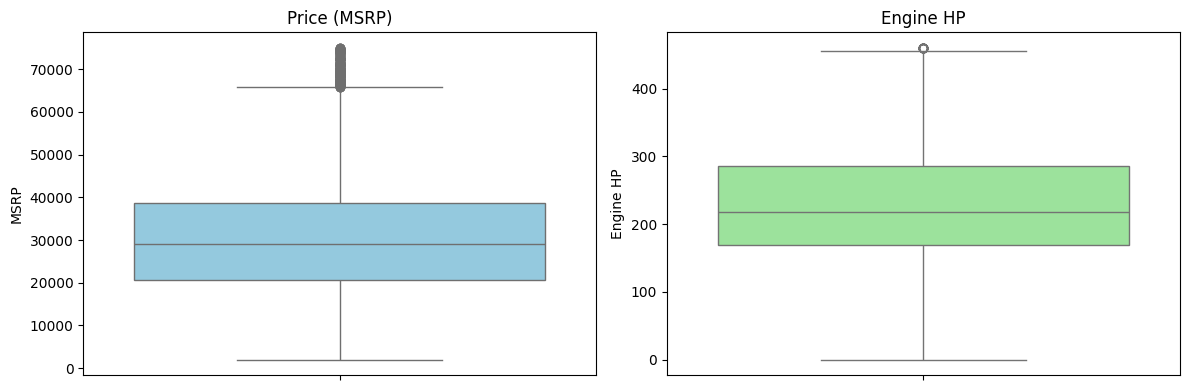

In [33]:
#find outliers
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['MSRP'], color='skyblue')
plt.title('Price (MSRP)')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['Engine HP'], color='lightgreen')
plt.title('Engine HP')

plt.tight_layout()
plt.show()

In [34]:
def remove_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return data[(data[column] >= lower) & (data[column] <= upper)]

before = len(df)
df = remove_outliers(df, 'MSRP')
df = remove_outliers(df, 'Engine HP')
df = df.reset_index(drop=True)

print("Rows before:", before)
print("Rows after :", len(df))
print("Rows removed:", before - len(df))

Rows before: 10177
Rows after : 9998
Rows removed: 179


In [35]:
#final check of the clean data
print("Clean data shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
df.head()

Clean data shape: (9998, 17)
Missing values: 0
Duplicates: 0


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP,avg_mpg
0,BMW,1 Series M,2011,premium unleaded (required),335,6,MANUAL,rear wheel drive,2,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135,22.5
1,BMW,1 Series,2011,premium unleaded (required),300,6,MANUAL,rear wheel drive,2,"Luxury,Performance",Compact,Convertible,28,19,3916,40650,23.5
2,BMW,1 Series,2011,premium unleaded (required),300,6,MANUAL,rear wheel drive,2,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350,24.0
3,BMW,1 Series,2011,premium unleaded (required),230,6,MANUAL,rear wheel drive,2,"Luxury,Performance",Compact,Coupe,28,18,3916,29450,23.0
4,BMW,1 Series,2011,premium unleaded (required),230,6,MANUAL,rear wheel drive,2,Luxury,Compact,Convertible,28,18,3916,34500,23.0


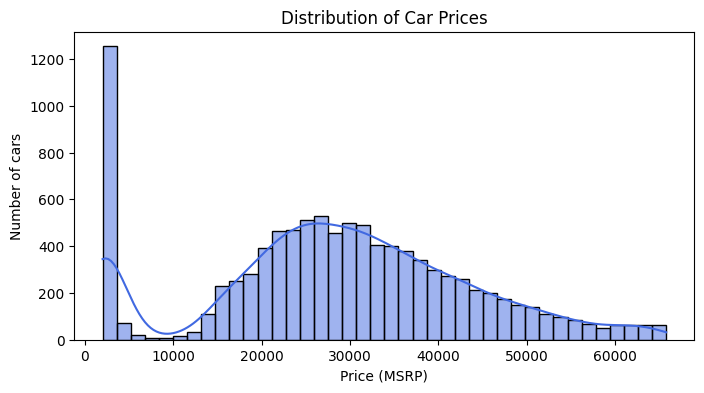

In [36]:
#graphs(data visualization)
#how are prices spread?
plt.figure(figsize=(8, 4))
sns.histplot(df['MSRP'], bins=40, kde=True, color='royalblue')
plt.title('Distribution of Car Prices')
plt.xlabel('Price (MSRP)')
plt.ylabel('Number of cars')
plt.show()

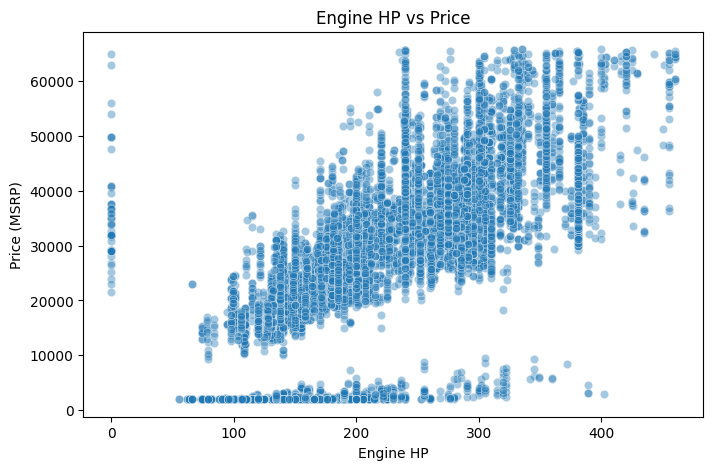

In [37]:
#Engine Hp vs price
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Engine HP', y='MSRP', data=df, alpha=0.4)
plt.title('Engine HP vs Price')
plt.xlabel('Engine HP')
plt.ylabel('Price (MSRP)')
plt.show()

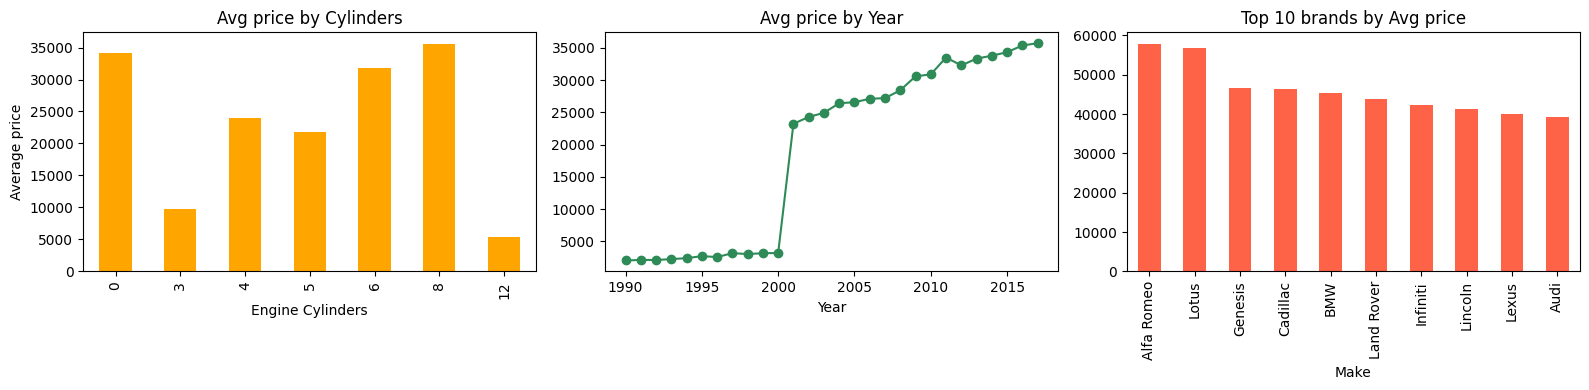

In [38]:
# Average price by cylinders, year and brand
plt.figure(figsize=(16, 4))

plt.subplot(1, 3, 1)
df.groupby('Engine Cylinders')['MSRP'].mean().plot(kind='bar', color='orange')
plt.title('Avg price by Cylinders')
plt.ylabel('Average price')

plt.subplot(1, 3, 2)
df.groupby('Year')['MSRP'].mean().plot(kind='line', color='seagreen', marker='o')
plt.title('Avg price by Year')

plt.subplot(1, 3, 3)
df.groupby('Make')['MSRP'].mean().sort_values(ascending=False).head(10).plot(kind='bar', color='tomato')
plt.title('Top 10 brands by Avg price')

plt.tight_layout()
plt.show()

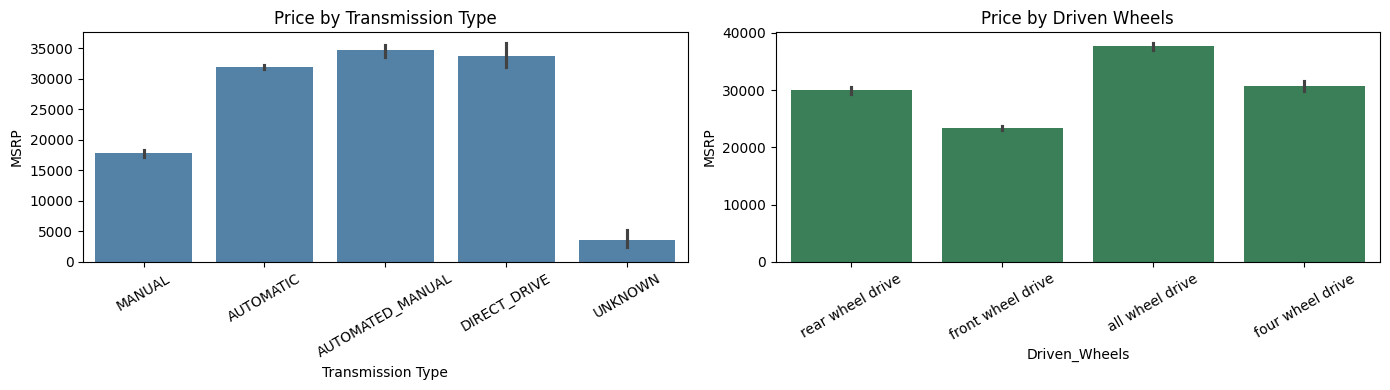

In [39]:
# Does transmission / drive type change the price?
plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
sns.barplot(x='Transmission Type', y='MSRP', data=df, color='steelblue')
plt.title('Price by Transmission Type')
plt.xticks(rotation=30)

plt.subplot(1, 2, 2)
sns.barplot(x='Driven_Wheels', y='MSRP', data=df, color='seagreen')
plt.title('Price by Driven Wheels')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

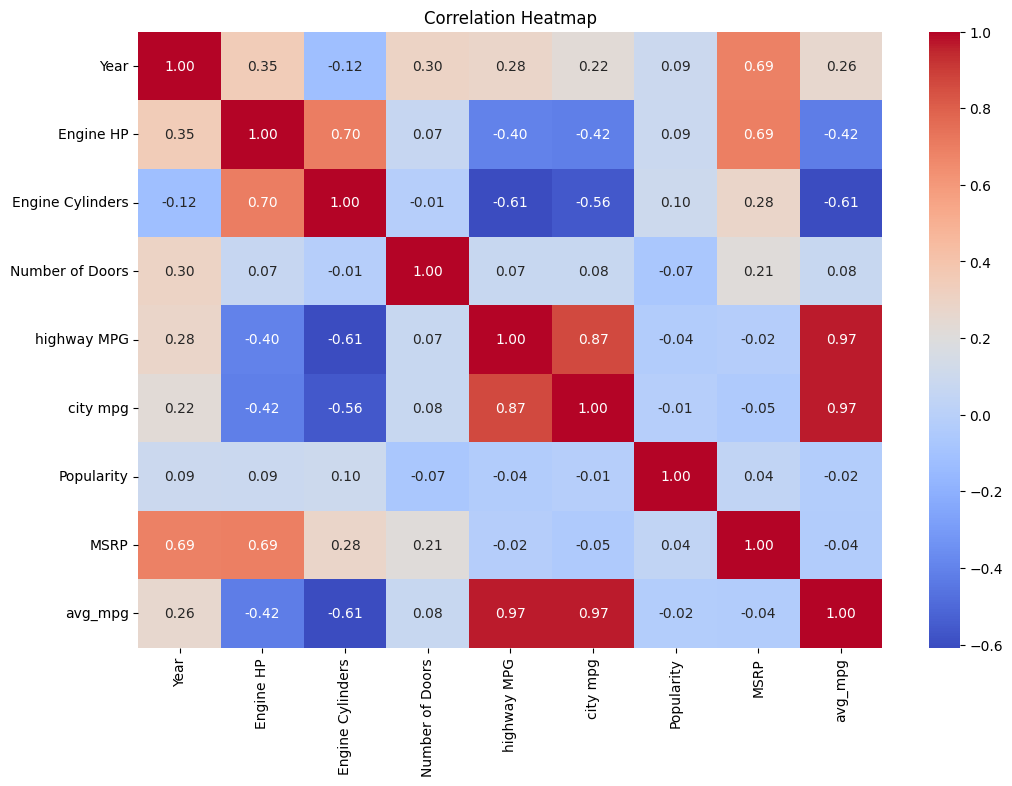

MSRP                1.000000
Engine HP           0.692753
Year                0.687376
Engine Cylinders    0.278469
Number of Doors     0.212893
Popularity          0.040936
highway MPG        -0.022867
avg_mpg            -0.035742
city mpg           -0.045888
Name: MSRP, dtype: float64


In [40]:
# Correlation heatmap
# Shows which columns are most related to price. Closer to 1 = strong positive relation.
num_df = df.select_dtypes(include='number')     # only number columns

plt.figure(figsize=(12, 8))
sns.heatmap(num_df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

# Top factors affecting price
print(num_df.corr()['MSRP'].sort_values(ascending=False))

In [41]:
# PRICE PREDICTION
# Turn text columns into numbers
df_model = df.drop(columns=['Model', 'Market Category'])

text_cols = ['Make', 'Engine Fuel Type', 'Transmission Type',
             'Driven_Wheels', 'Vehicle Size', 'Vehicle Style']

df_model = pd.get_dummies(df_model, columns=text_cols, dtype=int)

print("Shape after converting text to numbers:", df_model.shape)
df_model.head()

Shape after converting text to numbers: (9998, 84)


,Year,Engine HP,Engine Cylinders,Number of Doors,highway MPG,city mpg,Popularity,MSRP,avg_mpg,Make_Acura,...,Vehicle Style_Convertible,Vehicle Style_Convertible SUV,Vehicle Style_Coupe,Vehicle Style_Crew Cab Pickup,Vehicle Style_Extended Cab Pickup,Vehicle Style_Passenger Minivan,Vehicle Style_Passenger Van,Vehicle Style_Regular Cab Pickup,Vehicle Style_Sedan,Vehicle Style_Wagon
0,2011,335,6,2,26,19,3916,46135,22.5,0,...,0,0,1,0,0,0,0,0,0,0
1,2011,300,6,2,28,19,3916,40650,23.5,0,...,1,0,0,0,0,0,0,0,0,0
2,2011,300,6,2,28,20,3916,36350,24.0,0,...,0,0,1,0,0,0,0,0,0,0
3,2011,230,6,2,28,18,3916,29450,23.0,0,...,0,0,1,0,0,0,0,0,0,0
4,2011,230,6,2,28,18,3916,34500,23.0,0,...,1,0,0,0,0,0,0,0,0,0


In [42]:
# Choose inputs (X) and the answer (y)
# X = things we know about the car
# y = the price we want to predict
X = df_model.drop(columns=['MSRP'])
y = df_model['MSRP']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (9998, 83)
y shape: (9998,)


In [44]:
#  Split into Training data (80%) and Testing data (20%)
# The model learns from training data and is checked on testing data it has never seen.
from sklearn.model_selection import train_test_split   # split data into train and test
from sklearn.linear_model import LinearRegression      # our prediction model
from sklearn.metrics import r2_score, mean_absolute_error

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

Training rows: 7998
Testing rows : 2000


In [45]:
#Train the model (Linear Regression)
model = LinearRegression()
model.fit(X_train, y_train)      # the model learns here

print("Model trained ✅")

Model trained ✅


In [46]:
#Check how good the model is
y_pred = model.predict(X_test)

r2  = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"R² Score : {r2:.2f}   (closer to 1 = better)")
print(f"Average error (MAE): {mae:,.0f}   (on average the prediction is off by this much)")

R² Score : 0.83   (closer to 1 = better)
Average error (MAE): 4,730   (on average the prediction is off by this much)


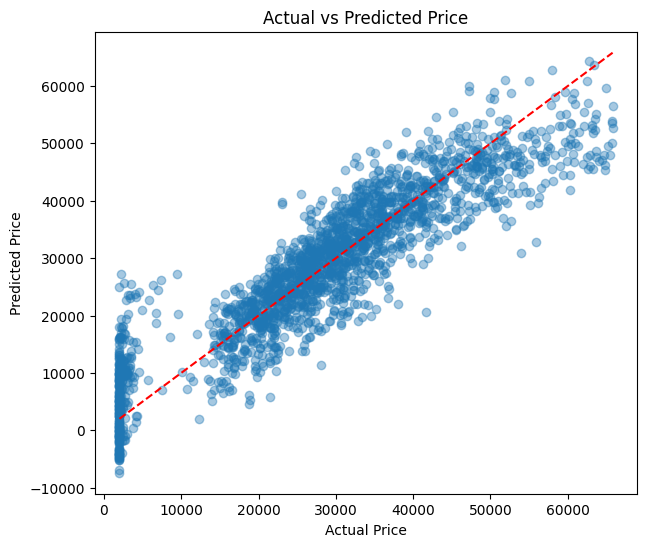

In [47]:
#Actual price vs Predicted price
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted Price')
plt.show()

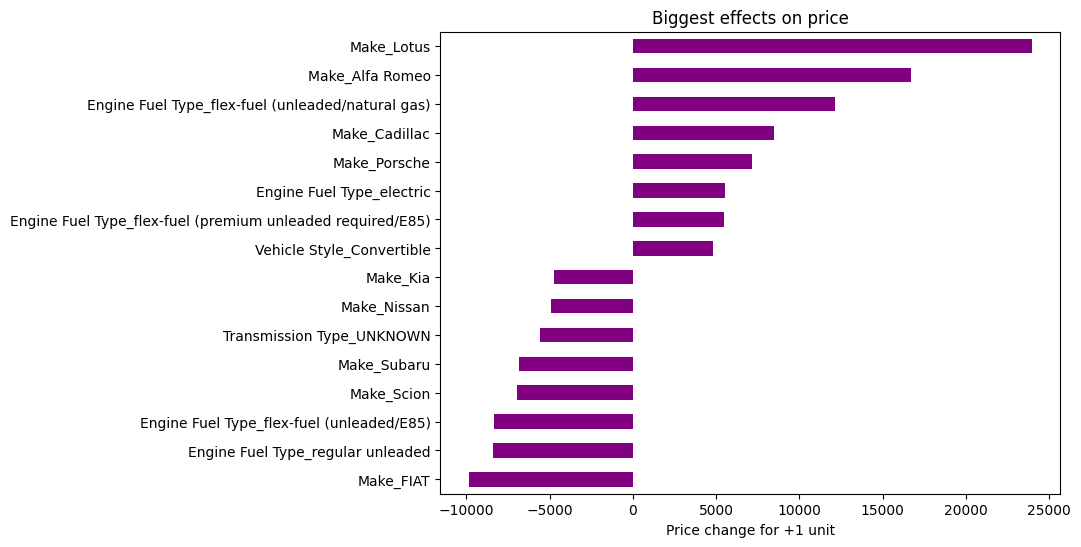

In [48]:
# Which features matter most?
coef = pd.Series(model.coef_, index=X.columns).sort_values()
top = pd.concat([coef.head(8), coef.tail(8)])     # 8 most negative + 8 most positive

plt.figure(figsize=(8, 6))
top.plot(kind='barh', color='purple')
plt.title('Biggest effects on price')
plt.xlabel('Price change for +1 unit')
plt.show()

In [50]:
#  Predict the price of YOUR car

# Start with a row of zeros for every column the model knows
new_car = pd.DataFrame(0, index=[0], columns=X.columns)

# Number inputs
new_car['Year'] = 2016
new_car['Engine HP'] = 250
new_car['Engine Cylinders'] = 4
new_car['Number of Doors'] = 4
new_car['highway MPG'] = 32
new_car['city mpg'] = 22
new_car['Popularity'] = 2000
new_car['avg_mpg'] = (32 + 22) / 2

# Text inputs -> put 1 in the matching column
new_car['Make_BMW'] = 1
new_car['Engine Fuel Type_premium unleaded (recommended)'] = 1
new_car['Transmission Type_AUTOMATIC'] = 1
new_car['Driven_Wheels_rear wheel drive'] = 1
new_car['Vehicle Size_Midsize'] = 1
new_car['Vehicle Style_Sedan'] = 1

predicted_price = model.predict(new_car)[0]
print(f" Predicted price: ${predicted_price:,.0f}")

 Predicted price: $40,720
